# Gauge-covariant neural decoding of the toric code

*An interactive introduction, written for the* `lossy-toric-codes` *repository.*

This notebook tutorial builds a neural decoder for the toric code that respects the symmetries of the
optimal decoder **exactly**, by reading the decoding problem as a $\mathbb{Z}_2$ lattice gauge theory. We
start from what a decoder has to do, compute the *exact* optimal decoder on a small lattice by brute force,
translate everything into gauge-theory language (error chains are link fields, stabilizers are gauge
transformations, the syndrome is the plaquette field, logical operators are Polyakov loops), and then build,
check and train a gauge-covariant CNN. We compare it with minimum-weight perfect matching (MWPM) and with the
exact optimum on the same noise samples.

The style follows *Introduction to Normalizing Flows for Lattice Field Theory* (Albergo, Boyda, Hackett, Kanwar,
Cranmer, Racanière, Rezende, Shanahan, arXiv:2101.08176): read the notebook as a single annotated program,
executed from top to bottom without clearing the scope. Cells marked **Try it** invite you to change something
and re-run.

## I. Setup

We import common packages and define a few utilities. Readers may safely execute and skip over this section.

The lattice code (toric code, noise, MWPM decoder) comes from the repository's package `lossytoric`; install it
from the repository root with `pip install -e .`. The neural network is written in JAX (`pip install jax optax`).

In [1]:
import sys, time, pathlib
import numpy as np

try:
    import lossytoric
except ImportError:                       # running from notebooks/ without `pip install -e .`
    sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
from lossytoric.toric import ToricCode, h_edge, v_edge
from lossytoric.noise import sample_errors
from lossytoric.decoder import ErasureMWPM

import jax
import jax.numpy as jnp
import optax
print(f"JAX VERSION: {jax.__version__}, devices: {jax.devices()}")

%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

JAX VERSION: 0.12.1, devices: [CpuDevice(id=0)]


Two small helpers: a binomial standard error for failure rates, and the live-updating plot used during
training (it updates one figure in place, like the ESS/loss plot in the flows tutorial).

In [2]:
def binom_se(rate, n):
    return np.sqrt(rate * (1 - rate) / n)

def init_live_plot(n_steps, ref_lines, figsize=(8, 3.6)):
    fig, (ax_l, ax_f) = plt.subplots(1, 2, figsize=figsize)
    loss_line, = ax_l.plot([], [], color="#1c5cab")
    ax_l.set_xlim(0, n_steps); ax_l.set_xlabel("step"); ax_l.set_ylabel("training loss (BCE)")
    net_line, = ax_f.plot([], [], "o-", color="#1c5cab", label="network")
    for name, (y, c) in ref_lines.items():
        ax_f.axhline(y, color=c, ls="--", lw=1.2, label=name)
    ax_f.set_xlim(0, n_steps); ax_f.set_xlabel("step"); ax_f.set_ylabel("logical failure rate (validation)")
    ax_f.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    handle = display(fig, display_id=True)
    plt.close(fig)
    return dict(fig=fig, ax_l=ax_l, ax_f=ax_f, loss_line=loss_line, net_line=net_line, handle=handle)

def update_live_plot(lp, hist):
    lp["loss_line"].set_data(hist["loss_step"], hist["loss"])
    lp["net_line"].set_data(hist["val_step"], hist["val_fail"])
    for ax in (lp["ax_l"], lp["ax_f"]):
        ax.relim(); ax.autoscale_view(scalex=False)
    lp["handle"].update(lp["fig"])

## II. Notation

This section is a reference; everything is defined in detail below.

**Toric code** (conventions of `lossytoric/toric.py`)
* $L\times L$ periodic square lattice; $n = 2L^2$ qubits on the edges, $L^2$ $Z$-type checks on the vertices.
* Vertex $(i,j)$: row $i$, column $j$. Horizontal edge $h(i,j)$: $(i,j)\!-\!(i,j{+}1)$. Vertical edge $v(i,j)$: $(i,j)\!-\!(i{+}1,j)$.
* An $X$-error **chain** $E\in\{0,1\}^n$; its **syndrome** $s = HE \bmod 2$ (the vertices at the chain's ends).
* **Stabilizers** $S$: the $X$-plaquettes, i.e. the boundaries of faces. **Logicals** $\ell_0,\ell_1$: chains winding the torus.
* A **class** of chains: $\{E + S + a\,\ell_0 + b\,\ell_1\}$ for fixed $(a,b)\in\{0,1\}^2$, relative to a reference chain.

**Noise**: each qubit is erased with probability $e$ (heralded; the decoder knows where), otherwise flipped with
probability $p$. An erased qubit is flipped with probability $1/2$.

**Gauge-theory language** (Section IV)
* Link field $U = (-1)^{E}$ on the links of the **dual** lattice (dual sites = faces, dual links cross edges).
* Gauge transformation $\Omega$: flip the four dual links at one dual site = add one stabilizer.
* Plaquette $U_P$ of the dual lattice = the syndrome bit at the primal vertex inside it.
* Polyakov loops $P_0(j)$, $P_1(i)$: products of $U$ along dual lines that wrap the torus = the logical-$Z$ measurements.
* $\Delta F_x(C) = \ln Z(C) - \ln Z(C+\ell_x)$: the free-energy difference between the reference class and the class
  shifted by a logical; the optimal decoder keeps the reference class in direction $x$ iff $\Delta F_x > 0$.

**Network** (Section V): logit $z_x$; $z_x>0$ means "keep the reference class in direction $x$".

## III. The decoding problem

### A. The toric code in one picture

Qubits live on edges, checks on vertices. An $X$ error on an edge flips the two checks at its ends, so a chain
of errors only lights up the two checks at its ends: the decoder sees the **syndrome** (the lit dots), never
the chain itself. Let us draw one noisy sample.

L = 4: 32 qubits, 16 checks


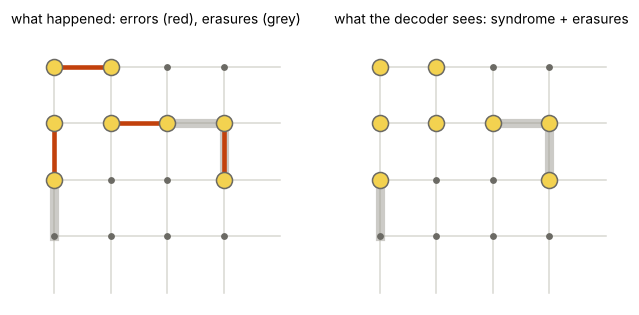

In [3]:
L = 4
code = ToricCode(L)
H = code.check_matrix()
Hd = H.toarray().astype(np.int64)
n = code.n_qubits
print(f"L = {L}: {n} qubits, {code.n_checks} checks")

def edge_coords(L):
    # endpoints (x0, y0, x1, y1) of every edge; vertex (i, j) is drawn at x = j, y = -i
    c = np.zeros((2 * L * L, 4))
    for i in range(L):
        for j in range(L):
            c[h_edge(i, j, L)] = (j, -i, j + 1, -i)
            c[v_edge(i, j, L)] = (j, -i, j, -i - 1)
    return c

def draw_sample(ax, L, err=None, corr=None, erased=None, syn=None, polyakov=False, title=""):
    ec = edge_coords(L)
    for x0, y0, x1, y1 in ec:
        ax.plot([x0, x1], [y0, y1], color="#d9d8d2", lw=1, zorder=1)
    if erased is not None:
        for k in np.flatnonzero(erased):
            x0, y0, x1, y1 = ec[k]; ax.plot([x0, x1], [y0, y1], color="#9a9890", lw=6, alpha=0.5, zorder=2)
    if err is not None:
        for k in np.flatnonzero(err):
            x0, y0, x1, y1 = ec[k]; ax.plot([x0, x1], [y0, y1], color="#c2410c", lw=3, zorder=3)
    if corr is not None:
        for k in np.flatnonzero(corr):
            x0, y0, x1, y1 = ec[k]; ax.plot([x0, x1], [y0, y1], color="#1c5cab", lw=2, ls="--", zorder=4)
    xs, ys = np.meshgrid(np.arange(L), -np.arange(L))
    ax.scatter(xs, ys, s=12, color="#6b6a64", zorder=5)
    if syn is not None:
        lit = np.flatnonzero(syn)
        ax.scatter(lit % L, -(lit // L), s=110, facecolor="#f3d250", edgecolor="#6b6a64", zorder=6)
    if polyakov:
        ax.plot([0.5, 0.5], [0.4, -L + 0.6], color="#7f77dd", lw=1.5, ls=":", zorder=0)
        ax.plot([-0.4, L - 0.6], [-0.5, -0.5], color="#7f77dd", lw=1.5, ls=":", zorder=0)
    ax.set_aspect("equal"); ax.axis("off"); ax.set_title(title, fontsize=9)
    ax.set_xlim(-0.6, L + 0.2); ax.set_ylim(-L - 0.2, 0.6)

rng = np.random.default_rng(7)
erased, err = sample_errors(n, 0.08, 0.1, 1, rng)
syn = (err.astype(np.int64) @ Hd.T) % 2
fig, ax = plt.subplots(1, 2, figsize=(7, 3.4))
draw_sample(ax[0], L, err=err[0], erased=erased[0], syn=syn[0], title="what happened: errors (red), erasures (grey)")
draw_sample(ax[1], L, erased=erased[0], syn=syn[0], title="what the decoder sees: syndrome + erasures")
plt.show()

NOTE: the lattice is periodic. An edge drawn to column $L$ (or row $L$) re-enters on the opposite side.

### B. Matching: the most likely *error*

MWPM pairs up the lit checks along the cheapest paths, with cost $\log\frac{1-p}{p}$ per ordinary edge and
cost $0$ per erased edge (an erased qubit is random anyway), and flips the qubits on those paths. The error
plus the correction then has no syndrome: it is a set of closed loops. Small loops are stabilizers and
harmless. A loop that **winds around the torus** is a logical operator: the decoder has failed.

residual syndrome after correction: 0
winding of error + correction: [1 1] -> logical error: the loop error + correction winds around the torus (this sample was chosen to show one)


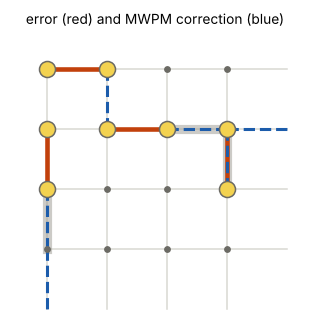

In [4]:
mwpm = ErasureMWPM(H)

def winding(chain):
    # (shots, 2): winding of a closed chain, measured by the two logical-Z rows
    return (chain.astype(np.int64) @ code.logical_z().T.astype(np.int64)) % 2

corr = mwpm.decode_batch(syn, erased)
print("residual syndrome after correction:", ((err ^ corr).astype(np.int64) @ Hd.T % 2).sum())
w = winding(err ^ corr)[0]
print("winding of error + correction:", w, "->", "success" if not w.any() else
      "logical error: the loop error + correction winds around the torus (this sample was chosen to show one)")

fig, ax = plt.subplots(1, 1, figsize=(3.6, 3.4))
draw_sample(ax, L, err=err[0], corr=corr[0], erased=erased[0], syn=syn[0], title="error (red) and MWPM correction (blue)")
plt.show()

### C. The optimal decoder: the most likely *class*

MWPM answers "which single error is most likely?". But many errors are equivalent: adding any stabilizer
$s$ to a chain changes nothing. The question that matters is "which **class** is most likely?". Relative to a
reference chain $C$ with the observed syndrome (we use the MWPM correction), the four classes are
$C + a\ell_0 + b\ell_1$, and their probabilities are sums over the stabilizer group $\mathcal S$:

$$
Z_{ab}(C) \;=\; \sum_{s\in\mathcal S} \Pr\big(C + s + a\ell_0 + b\ell_1\big),
\qquad
\Pr(E) \;\propto\; \prod_{\text{non-erased } k} \Big(\frac{p}{1-p}\Big)^{E_k}.
\tag{1}
$$

The optimal (maximum-likelihood) decoder picks the class with the largest $Z_{ab}$. Up to a sign, $\ln Z_{ab}$
is the free energy of a random-bond Ising model on the Nishimori line; that is how Phase 2a of the repository
computes optimal *thresholds*. For a small lattice we can simply enumerate $\mathcal S$: at $L=4$ it has
$2^{L^2-1} = 32768$ elements (the $L^2$ plaquettes multiply to the identity, so one is redundant).

Technical note: the Hamming weight of $C+\ell+s$ on the non-erased qubits is computed with two matrix
products, $|A\oplus s|_m = |A|_m + |s|_m - 2\,(A\wedge m)\cdot s$, chunked over shots to bound memory.

In [5]:
def logical_x(L):
    # the two winding chains: row 0 flips logical_z row 0 (h(0, j) for all j), row 1 flips row 1 (v(i, 0) for all i)
    lx = np.zeros((2, 2 * L * L), dtype=np.int64)
    for j in range(L): lx[0, h_edge(0, j, L)] = 1
    for i in range(L): lx[1, v_edge(i, 0, L)] = 1
    return lx

def stabilizer_group(code):
    P = code.plaquette_x()[:-1].astype(np.int64)
    k = P.shape[0]
    combos = (np.arange(2 ** k)[:, None] >> np.arange(k)) & 1
    return (combos @ P) % 2

lx = logical_x(L)
S_all = stabilizer_group(code)
CLASSES = [(0, 0), (1, 0), (0, 1), (1, 1)]          # class index k = a + 2 b

def class_logZ(C, erased, p, chunk=1000):
    # ln Z_ab(C) for the 4 classes, up to a constant common to all classes of one shot. (shots, 4)
    w = np.log(p / (1 - p))
    m = (~erased.astype(bool)).astype(np.float32)
    St = S_all.T.astype(np.float32)
    out = np.empty((len(C), 4))
    for a0 in range(0, len(C), chunk):
        mm = m[a0:a0 + chunk]
        sm = mm @ St
        for k, (a, b) in enumerate(CLASSES):
            A = ((C[a0:a0 + chunk] + a * lx[0] + b * lx[1]) % 2) * mm
            x = w * (A.sum(1)[:, None] + sm - 2 * (A @ St))
            mx = x.max(1, keepdims=True)
            out[a0:a0 + chunk, k] = mx[:, 0] + np.log(np.exp(x - mx).sum(1))
    return out

assert len(S_all) == 2 ** (L * L - 1) and not ((S_all @ Hd.T) % 2).any(), "stabilizers must have no syndrome"

Now a fair comparison: sample noise, decode with MWPM, and let the exact optimal decoder choose a class on the
same shots. The *true* class of a shot is the winding of error + reference.

In [6]:
P_NOISE, E_ERASE = 0.06, 0.1

def make_shots(N, p, e, seed):
    rng = np.random.default_rng(seed)
    erased, err = sample_errors(n, p, e, N, rng)
    syn = (err.astype(np.int64) @ Hd.T) % 2
    C = mwpm.decode_batch(syn, erased).astype(np.int64)        # reference chain: the MWPM correction
    true_ab = winding(err ^ C)                                  # (N, 2): which class actually happened
    return dict(err=err, erased=erased, syn=syn, C=C, true_ab=true_ab)

t0 = time.time()
test = make_shots(20_000, P_NOISE, E_ERASE, seed=12345)
test["logZ"] = class_logZ(test["C"], test["erased"], P_NOISE)
true_k = test["true_ab"][:, 0] + 2 * test["true_ab"][:, 1]
fail_mwpm = (true_k != 0).mean()
fail_opt = (test["logZ"].argmax(1) != true_k).mean()
N_test = len(true_k)
print(f"L={L}, p={P_NOISE}, e={E_ERASE}, {N_test} shots ({time.time() - t0:.0f}s)")
print(f"  MWPM            logical failure {fail_mwpm:.4f} +- {binom_se(fail_mwpm, N_test):.4f}")
print(f"  exact optimal   logical failure {fail_opt:.4f} +- {binom_se(fail_opt, N_test):.4f}"
      f"   ({(fail_opt - fail_mwpm) / fail_mwpm:+.1%} relative to MWPM)")

L=4, p=0.06, e=0.1, 20000 shots (49s)
  MWPM            logical failure 0.1601 +- 0.0026
  exact optimal   logical failure 0.1489 +- 0.0025   (-7.0% relative to MWPM)


The gap between the two lines is what *degeneracy* is worth: counting all equivalent errors, rather than only
the shortest one. A learned decoder can at best close this gap. Brute force stops working quickly (at $L=5$ the
group already has $2^{24}$ elements), which is why we want a network that learns the optimal decision.

**Try it:** change `P_NOISE` or `E_ERASE` and re-run the last cell. Where is the relative gap largest?

## IV. The gauge-theory dictionary

### A. Error chains are $\mathbb{Z}_2$ link fields, stabilizers are gauge transformations

Draw the **dual** lattice: one dual site in the middle of every face, one dual link crossing every edge. A chain
$E$ becomes a link field $U_\ell = (-1)^{E_\ell}$ on the dual links. Adding the stabilizer of one face flips the
four edges around it, i.e. the four dual links that meet at that dual site:

$$
U_\mu(x) \;\to\; \Omega(x)\, U_\mu(x)\, \Omega(x+\hat\mu), \qquad \Omega(x) = \pm 1 .
\tag{2}
$$

That is exactly a $\mathbb{Z}_2$ gauge transformation. **Equivalent errors are gauge-equivalent link fields.**

### B. The syndrome is the plaquette field, the logicals are Polyakov loops

A dual plaquette surrounds one primal vertex, and the product of the four dual links around it is
$(-1)^{\text{(parity of the chain at that vertex)}}$: the **syndrome bit**. Gauge transformations leave plaquettes
unchanged, which is the statement that stabilizers have no syndrome.

The only other gauge-invariant objects on a torus are **Polyakov loops**, products of $U$ along a dual line that
wraps the torus:

$$
P_0(j) = \prod_{i} U\big(h(i,j)\big), \qquad P_1(i) = \prod_{j} U\big(v(i,j)\big).
\tag{3}
$$

$P_0(0)$ and $P_1(0)$ are precisely the logical-$Z$ measurements (`code.logical_z()`), drawn as purple dotted
lines below. Adding a winding chain $\ell_0$ flips every $P_0(j)$, and none of the $P_1$.

dictionary checks passed


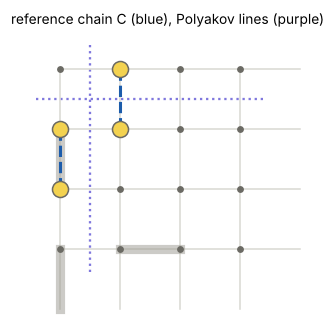

In [7]:
def features(C, erased):
    # chains (B, n) -> gauge invariants: x = [syndrome, erased h, erased v] (B, L, L, 3), P0 (B, L), P1 (B, L)
    C = C.astype(np.int64); erased = erased.astype(np.int64)
    B = C.shape[0]
    s = (C @ Hd.T % 2).reshape(B, L, L)                       # vertex (i, j)
    Ch, Cv = C[:, :L * L].reshape(B, L, L), C[:, L * L:].reshape(B, L, L)
    P0 = 1 - 2 * (Ch.sum(axis=1) % 2)                          # line j: h(i, j) for all i
    P1 = 1 - 2 * (Cv.sum(axis=2) % 2)                          # line i: v(i, j) for all j
    x = np.stack([s, erased[:, :L * L].reshape(B, L, L), erased[:, L * L:].reshape(B, L, L)], -1)
    return x.astype(np.float32), P0.astype(np.float32), P1.astype(np.float32)

C = test["C"][:500]; er = test["erased"][:500]
x, P0, P1 = features(C, er)
lz = winding(C)
assert np.array_equal(P0[:, 0], 1 - 2 * lz[:, 0]) and np.array_equal(P1[:, 0], 1 - 2 * lz[:, 1]), \
    "Polyakov loops at line 0 should be the logical-Z measurements"

S_rand = (np.random.default_rng(0).integers(0, 2, (500, L * L)) @ code.plaquette_x().astype(np.int64)) % 2
x2, Q0, Q1 = features((C + S_rand) % 2, er)
assert np.array_equal(x2, x) and np.array_equal(Q0, P0) and np.array_equal(Q1, P1), \
    "a gauge transformation (adding stabilizers) should leave syndrome and Polyakov loops unchanged"

_, R0, R1 = features((C + lx[0]) % 2, er)
assert np.array_equal(R0, -P0) and np.array_equal(R1, P1), "adding l_0 should flip every P_0 and no P_1"
print("dictionary checks passed")

fig, ax = plt.subplots(1, 1, figsize=(3.6, 3.4))
draw_sample(ax, L, corr=test["C"][0], erased=test["erased"][0], syn=test["syn"][0], polyakov=True,
            title="reference chain C (blue), Polyakov lines (purple)")
plt.show()

### C. The optimal decoder in gauge language

Write $\Delta F_x(C) = \ln Z(C) - \ln Z(C+\ell_x)$, marginalised over the other direction. The optimal decoder
keeps the reference class in direction $x$ iff $\Delta F_x(C) > 0$. Three exact symmetries follow from Eq. (1):

1. **Gauge invariance:** $\Delta F_x(C+s) = \Delta F_x(C)$ for every stabilizer $s$.
2. **Logical covariance:** $\Delta F_x(C+\ell_x) = -\Delta F_x(C)$ (the two classes swap roles).
3. **Translation invariance** on the torus (and, without erasure, the lattice rotations/reflections).

We can verify 2. numerically with the exact enumeration.

In [8]:
def delta_F(logZ):
    # marginal free-energy differences (shots, 2): keep vs flip in direction 0 and 1
    lse = lambda a, b: np.logaddexp(logZ[:, a], logZ[:, b])
    return np.stack([lse(0, 2) - lse(1, 3), lse(0, 1) - lse(2, 3)], axis=1)

dF = delta_F(class_logZ(C[:200], er[:200], P_NOISE))
dF_shift = delta_F(class_logZ((C[:200] + lx[0]) % 2, er[:200], P_NOISE))
assert np.allclose(dF_shift[:, 0], -dF[:, 0]) and np.allclose(dF_shift[:, 1], dF[:, 1])
print("Delta F_0 flips sign under C -> C + l_0; Delta F_1 is unchanged.  Example values:", np.round(dF[:4, 0], 2))

Delta F_0 flips sign under C -> C + l_0; Delta F_1 is unchanged.  Example values: [7.32 2.9  7.84 4.13]


### D. What a lattice-gauge-equivariant CNN reduces to for $\mathbb{Z}_2$

In an L-CNN (Favoni, Ipp, Müller, Schuh, PRL 128, 032003 (2022)), site features $W(x)$ (for example untraced
Wilson loops starting and ending at $x$) transform covariantly, $W(x)\to\Omega(x)W(x)\Omega(x)^\dagger$, and are
parallel-transported with the links. For an **abelian** group this action is trivial: $\Omega W\Omega^\dagger = W$.
Every closed-loop feature is already a gauge-invariant number, here a product of syndrome bits, and parallel
transport does nothing to it. On a torus, the only gauge-invariant information in the link field beyond the
plaquettes is the pair of holonomies. Hence:

$$
\text{every gauge-invariant decoder is a function } f\big(\,s,\ \text{erasure mask},\ P_0,\ P_1\big).
\tag{4}
$$

The covariant machinery collapses to "a CNN on the syndrome, plus Polyakov loops". It becomes non-trivial again
for non-abelian groups (Section VI).

## V. A gauge-covariant decoder

### A. The Polyakov readout

To make symmetry 2 exact, let the network output, for every Polyakov line $l$ of each direction, a
gauge-invariant number $G_x(l)$ computed from $(s, \text{erasure})$ alone, and read out

$$
z_x \;=\; \frac{1}{L}\sum_{l} P_x(l)\, G_x(l)
\qquad \text{(covariant)}, \qquad
z_x \;=\; B_x + \frac{1}{L}\sum_{l} P_x(l)\, G_x(l)
\qquad \text{(residual)} .
\tag{5}
$$

* $z_x$ is exactly gauge invariant (every ingredient is), exactly translation equivariant (circular
  convolutions, then averages), and in the covariant form **exactly odd** under $C\to C+\ell_x$, like $\Delta F_x$.
* The price of oddness: the network may only use the two holonomy bits of the reference chain, not "where MWPM
  put its paths". It has to decide the class from the syndrome itself.
* The residual form adds a gauge-invariant bias $B_x$ (a global average of a CNN map). It stays gauge invariant
  but is no longer odd: it can express "trust the reference unless the syndrome says otherwise".

$G_x(l)$ is obtained by averaging an output map of the CNN along the line $l$.

### B. Implementation

In [9]:
RESIDUAL = False         # Try it: True adds the gauge-invariant bias B_x (residual readout)
WIDTH, DEPTH = 32, 6

def init_params(key, width=WIDTH, depth=DEPTH, c_in=3, residual=RESIDUAL):
    params, c = [], c_in
    for d in range(depth):
        key, k = jax.random.split(key)
        c_out = (4 if residual else 2) if d == depth - 1 else width
        params.append((jax.random.normal(k, (3, 3, c, c_out)) * jnp.sqrt(2.0 / (9 * c)), jnp.zeros(c_out)))
        c = c_out
    return params

def conv_circular(x, w, b):
    xp = jnp.pad(x, ((0, 0), (1, 1), (1, 1), (0, 0)), mode="wrap")     # periodic padding: the torus
    return jax.lax.conv_general_dilated(xp, w, (1, 1), "VALID",
                                        dimension_numbers=("NHWC", "HWIO", "NHWC")) + b

@jax.jit
def logits(params, x, P0, P1):
    h = x
    for w, b in params[:-1]:
        h = jax.nn.gelu(conv_circular(h, w, b))
    g = conv_circular(h, *params[-1])                    # (B, L, L, 2 or 4)
    G0 = g[..., 0].mean(axis=1)                          # along line j (over i)
    G1 = g[..., 1].mean(axis=2)                          # along line i (over j)
    z = jnp.stack([(P0 * G0).mean(1), (P1 * G1).mean(1)], axis=1)
    if g.shape[-1] == 4:
        z = z + g[..., 2:].mean(axis=(1, 2))
    return z

def net_logits(params, C, erased, batch=4096):
    out = []
    for a in range(0, len(C), batch):
        x, P0, P1 = features(C[a:a + batch], erased[a:a + batch])
        out.append(np.asarray(logits(params, jnp.asarray(x), jnp.asarray(P0), jnp.asarray(P1))))
    return np.concatenate(out)

params = init_params(jax.random.PRNGKey(0))
print("parameters:", sum(w.size + b.size for w, b in params))

parameters: 38466


### C. Symmetry checks

Before any training, the symmetries must hold **exactly** for random weights.

In [10]:
def check_symmetries(params, residual):
    C, er = test["C"][:256], test["erased"][:256]
    z = net_logits(params, C, er)
    S_rand = (np.random.default_rng(1).integers(0, 2, (256, L * L)) @ code.plaquette_x().astype(np.int64)) % 2
    assert np.allclose(net_logits(params, (C + S_rand) % 2, er), z, atol=1e-5), \
        "gauge transformation should leave the output unchanged"
    def roll(v, k):          # translate the configuration by k rows
        h, w = v[:, :L * L].reshape(-1, L, L), v[:, L * L:].reshape(-1, L, L)
        return np.concatenate([np.roll(h, k, 1).reshape(-1, L * L), np.roll(w, k, 1).reshape(-1, L * L)], 1)
    assert np.allclose(net_logits(params, roll(C, 1), roll(er, 1)), z, atol=1e-5), \
        "a lattice translation should leave the output unchanged"
    z_l = net_logits(params, (C + lx[0]) % 2, er)
    assert np.allclose(z_l[:, 1], z[:, 1], atol=1e-5)
    if not residual:
        assert np.allclose(z_l[:, 0], -z[:, 0], atol=1e-5), "covariant readout should be odd under C -> C + l_0"
    print("symmetry checks passed", "(residual: gauge + translations)" if residual else "(covariant: gauge + translations + oddness)")

check_symmetries(init_params(jax.random.PRNGKey(1), residual=False), residual=False)
if RESIDUAL:
    check_symmetries(params, residual=True)

symmetry checks passed (covariant: gauge + translations + oddness)


### D. Training

Each shot gives two binary labels $t_x = 1$ if the reference class is right in direction $x$, and we minimise the
binary cross entropy of $z_x$. With exact symmetries the optimum of this loss is $z_x = \Delta F_x$, the
free-energy difference from Section IV C.

Technical note: **stream the data**. A fixed training set of a few $10^5$ shots overfits within a few passes:
during development, a net trained that way beat MWPM on its own training data (per-direction accuracy 0.939 vs
0.923) and lost to it on fresh data. Below, a new pool of shots is sampled every `REFRESH` steps, so each shot is
seen about once. Generating shots (MWPM with erasure-dependent weights) dominates the run time.

The run below takes roughly 10 minutes on a laptop CPU. The right panel tracks the logical failure rate on a
fixed validation set, together with MWPM and the exact optimum on the same shots.

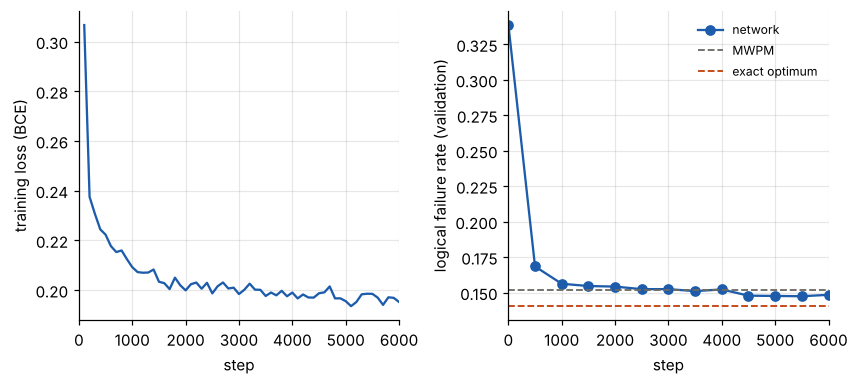

trained 6000 steps on 3,072,000 fresh shots in 459s


In [11]:
STEPS, BATCH, REFRESH, LR = 6000, 512, 100, 2e-3
EVAL_EVERY = 500

val = make_shots(5_000, P_NOISE, E_ERASE, seed=777)
val_k = val["true_ab"][:, 0] + 2 * val["true_ab"][:, 1]
val_fail_mwpm = (val_k != 0).mean()
val_fail_opt = (class_logZ(val["C"], val["erased"], P_NOISE).argmax(1) != val_k).mean()

def net_failure(params, shots):
    z = net_logits(params, shots["C"], shots["erased"])
    return ((z > 0) != (shots["true_ab"] == 0)).any(axis=1)

def loss_fn(params, b):
    return optax.sigmoid_binary_cross_entropy(logits(params, b["x"], b["P0"], b["P1"]), b["t"]).mean()

opt = optax.adam(optax.cosine_decay_schedule(LR, STEPS))

@jax.jit
def train_step(params, state, b):
    l, g = jax.value_and_grad(loss_fn)(params, b)
    u, state = opt.update(g, state, params)
    return optax.apply_updates(params, u), state, l

params = init_params(jax.random.PRNGKey(0))
state = opt.init(params)
hist = dict(loss_step=[], loss=[], val_step=[], val_fail=[])
lp = init_live_plot(STEPS, {"MWPM": (val_fail_mwpm, "#6b6a64"), "exact optimum": (val_fail_opt, "#c2410c")})
rng = np.random.default_rng(1)
t0, running = time.time(), []
for step in range(STEPS):
    if step % REFRESH == 0:
        pool = make_shots(REFRESH * BATCH, P_NOISE, E_ERASE, seed=10_000 + step)
        px, pP0, pP1 = features(pool["C"], pool["erased"])
        pt = (1 - pool["true_ab"]).astype(np.float32)
        perm = rng.permutation(REFRESH * BATCH)
    idx = perm[(step % REFRESH) * BATCH:(step % REFRESH + 1) * BATCH]
    batch = dict(x=jnp.asarray(px[idx]), P0=jnp.asarray(pP0[idx]), P1=jnp.asarray(pP1[idx]), t=jnp.asarray(pt[idx]))
    params, state, l = train_step(params, state, batch)
    running.append(float(l))
    if (step + 1) % 100 == 0:
        hist["loss_step"].append(step + 1); hist["loss"].append(np.mean(running)); running = []
    if (step + 1) % EVAL_EVERY == 0 or step == 0:
        hist["val_step"].append(step + 1); hist["val_fail"].append(net_failure(params, val).mean())
        update_live_plot(lp, hist)
print(f"trained {STEPS} steps on {STEPS * BATCH:,} fresh shots in {time.time() - t0:.0f}s")

### E. Evaluation

The decisive comparison uses the 20 000 test shots from Section III C, never seen in training. Because MWPM, the
network and the exact optimum decode the **same** shots, the honest error bar on a difference is the paired one:
it only counts shots on which two decoders disagree.

In [12]:
def paired(f_a, f_b):
    # change in failure rate from decoder a to decoder b on the same shots, with its paired standard error
    d = f_b.mean() - f_a.mean()
    return d, np.sqrt((f_a != f_b).sum()) / len(f_a)

f_mwpm = true_k != 0
f_opt = test["logZ"].argmax(1) != true_k
f_net = net_failure(params, test)
print(f"{'decoder':16s} logical failure")
for name, f in [("MWPM", f_mwpm), ("network", f_net), ("exact optimum", f_opt)]:
    print(f"{name:16s} {f.mean():.4f} +- {binom_se(f.mean(), N_test):.4f}")
d, se = paired(f_mwpm, f_net)
d_opt, _ = paired(f_mwpm, f_opt)
print(f"\nnetwork vs MWPM: {d:+.4f} +- {se:.4f} (paired); the network closes {d / d_opt:.0%} of the gap to the optimum")

decoder          logical failure
MWPM             0.1601 +- 0.0026
network          0.1544 +- 0.0026
exact optimum    0.1489 +- 0.0025

network vs MWPM: -0.0057 +- 0.0020 (paired); the network closes 51% of the gap to the optimum


With exact symmetries, the BCE optimum is $z_x = \Delta F_x$. So the network's logits can be compared directly with
the exact free-energy differences of Section IV C, shot by shot:

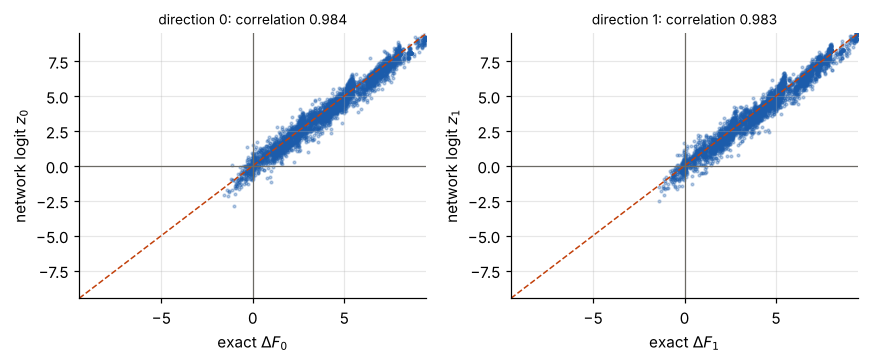

In [13]:
z_test = net_logits(params, test["C"], test["erased"])
dF_test = delta_F(test["logZ"])
fig, ax = plt.subplots(1, 2, figsize=(8, 3.4))
for k in range(2):
    ax[k].scatter(dF_test[:4000, k], z_test[:4000, k], s=3, alpha=0.3, color="#1c5cab")
    lim = np.percentile(np.abs(dF_test[:, k]), 99)
    ax[k].plot([-lim, lim], [-lim, lim], color="#c2410c", lw=1, ls="--")
    ax[k].set_xlim(-lim, lim); ax[k].set_ylim(-lim, lim)
    ax[k].axhline(0, color="#6b6a64", lw=0.8); ax[k].axvline(0, color="#6b6a64", lw=0.8)
    ax[k].set_xlabel(rf"exact $\Delta F_{k}$"); ax[k].set_ylabel(rf"network logit $z_{k}$")
    r = np.corrcoef(dF_test[:, k], z_test[:, k])[0, 1]
    ax[k].set_title(f"direction {k}: correlation {r:.3f}", fontsize=9)
fig.tight_layout(); plt.show()

Points in the upper-left and lower-right quadrants are shots where the network and the optimal decoder disagree.
The network was never shown a free energy, only right/wrong labels; it recovers $\Delta F$ because that is what
the symmetric BCE optimum is.

**Try it:**
* Set `RESIDUAL = True` (Section V B) and re-run from there: the residual readout may lean on the MWPM reference instead of deciding from the syndrome alone.
* Replace the streamed pools by one fixed pool of $3\cdot10^5$ shots and watch the validation curve turn upwards (overfitting).
* Evaluate the trained network on $L=6$ shots: it is translation equivariant and size agnostic, but its receptive field (`DEPTH`) was chosen for $L=4$.

### F. Interactive explorer

Pick a shot and compare the three decoders. The verdict line shows the true class and each decoder's choice,
as $(a,b)$ relative to the MWPM reference.

shots where the network fixes an MWPM failure: [  6  37  53  86 100 127 132 150 157 167]


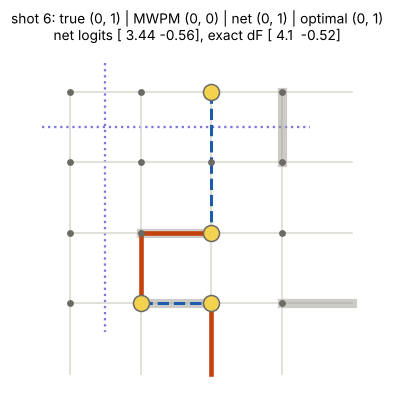

interactive(children=(IntSlider(value=0, continuous_update=False, description='shot', max=19999), Output()), _…

In [14]:
def explore(shot=0):
    k = int(shot)
    zt = net_logits(params, test["C"][k:k + 1], test["erased"][k:k + 1])[0]
    net_ab = tuple(int(v) for v in (zt < 0))
    opt_ab = CLASSES[int(test["logZ"][k].argmax())]
    true_ab = tuple(int(v) for v in test["true_ab"][k])
    fig, ax = plt.subplots(1, 1, figsize=(4.2, 4.0))
    draw_sample(ax, L, err=test["err"][k], corr=test["C"][k], erased=test["erased"][k], syn=test["syn"][k], polyakov=True,
                title=f"shot {k}: true {true_ab} | MWPM (0, 0) | net {net_ab} | optimal {opt_ab}\n"
                      f"net logits {np.round(zt, 2)}, exact dF {np.round(dF_test[k], 2)}")
    plt.show()

interesting = np.flatnonzero(f_mwpm & ~f_net)          # MWPM fails, the network fixes it
print("shots where the network fixes an MWPM failure:", interesting[:10])
explore(interesting[0] if len(interesting) else 0)

try:
    import ipywidgets as widgets
    widgets.interact(explore, shot=widgets.IntSlider(0, 0, N_test - 1, 1, continuous_update=False))
except ImportError:
    print("pip install ipywidgets for the slider; meanwhile call explore(shot) by hand")

## VI. Outlook

* **Faulty measurements.** With readout errors the syndrome is measured for $T$ rounds and errors become chains in
  a 3D spacetime lattice. The error field becomes a 2-form on the dual lattice (couplings on plaquettes), gauge
  transformations live on links, and the local invariants are the detection events. The optimal-threshold side is
  the random-plaquette gauge model in `src/lossytoric/rpgm.py`; the decoder side is the 3D analogue of Eq. (5).
* **Free energies and flows.** The network approximates $\Delta F_x$. Training on exact or Monte Carlo estimates of
  $\Delta F$ (regression instead of labels) and estimating $\Delta F$ itself with learned non-equilibrium methods
  (stochastic normalizing flows, Jarzynski-type annealing of the seam couplings) connects this notebook to the
  flows tutorial it imitates. For $\mathbb Z_2$ variables the flow must be stochastic or discrete.
* **Non-abelian codes.** For the group surface codes of Manjunath, Mattei, Tiwari and Ellison (arXiv:2603.05502),
  the errors are $G$-valued link fields (e.g. $G = D_4$), the syndrome is a field of fluxes transforming by
  conjugation, and $\Omega W \Omega^\dagger \neq W$: there the full L-CNN machinery is needed, not its abelian shadow.

## VII. References

1. E. Dennis, A. Kitaev, A. Landahl, J. Preskill, *Topological quantum memory*, J. Math. Phys. 43, 4452 (2002).
2. M. S. Albergo et al., *Introduction to normalizing flows for lattice field theory*, arXiv:2101.08176.
3. M. Favoni, A. Ipp, D. I. Müller, D. Schuh, *Lattice gauge equivariant convolutional neural networks*, PRL 128, 032003 (2022).
4. E. Egorov, R. Bondesan, M. Welling, *The END: an equivariant neural decoder for quantum error correction*, arXiv:2304.07362.
5. O. Higgott, C. Gidney, *Sparse Blossom: correcting a million errors per core second with minimum-weight matching* (PyMatching 2), arXiv:2303.15933.
6. N. Manjunath, A. Mattei, A. Tiwari, T. D. Ellison, *Universal quantum computation with group surface codes*, arXiv:2603.05502.